# Exo finger characterization: alone vs with the hand
Run this notebook from the repo root (next to `characterize_motor_flex.py`). It uses the latest `alone_*.csv` and `hand_*.csv` in `characterization/`.

In [17]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from characterize_motor_flex import load_visits

%matplotlib inline

OUT    = "characterization"   # folder with the CSVs
SETTLE = 2.0                  # s discarded at the start of each dwell
SKIP   = 1                    # initial cycles excluded (conditioning)
DEG    = 2                    # polynomial degree of the model
COLORS = {"alone": "tab:blue", "hand": "tab:red"}

files = {}
for s in ("alone", "hand"):
    found = sorted(glob.glob(f"{OUT}/{s}_*.csv"))
    if found:
        files[s] = found[-1]          # latest run
files

{'alone': 'characterization/alone_20261125_150232.csv',
 'hand': 'characterization/hand_20261125_151647.csv'}

## 1. Load data and fit the models

In [18]:
data, rows = {}, []
for name, path in files.items():
    meta, visits = load_visits(path, SETTLE)
    inc = [v for v in visits if v["cycle"] >= SKIP + 1] or [v for v in visits if v["cycle"] >= 1]
    R_ref = np.mean([v["R"] for v in inc if v["step"] == 0])       # open end -> 0 %
    df = pd.DataFrame(inc)
    df["x"] = (df.R - R_ref) / R_ref * 100                          # dR/R [%]

    c_fwd = np.polyfit(df.pos, df.x, DEG)                           # pos -> dR/R
    c_inv = np.polyfit(df.x, df.pos, DEG)                           # dR/R -> pos
    rms   = np.sqrt(np.mean((df.x - np.polyval(c_fwd, df.pos)) ** 2))
    rms_t = np.sqrt(np.mean((df.pos - np.polyval(c_inv, df.x)) ** 2))

    m = df.groupby(["dir", "step"]).x.mean().unstack(0)
    N = df.step.max()
    hyst = (m.fwd - m.back).abs().loc[1:N - 1].dropna()
    rep = df.groupby(["dir", "step"]).x.std().mean()

    data[name] = dict(df=df, R_ref=R_ref, c_fwd=c_fwd, c_inv=c_inv, N=N)
    rows.append({"setting": name, "R_ref [kOhm]": R_ref / 1000,
                 "span [%]": abs(np.polyval(c_fwd, df.pos.max()) - np.polyval(c_fwd, df.pos.min())),
                 "fit RMS [%]": rms, "fit RMS [ticks]": rms_t,
                 "hysteresis max [%]": hyst.max(), "hysteresis mean [%]": hyst.mean(),
                 "repeatability std [%]": rep})
pd.DataFrame(rows).set_index("setting").round(2).T

setting,alone,hand
R_ref [kOhm],31.33,43.26
span [%],165.53,88.20
fit RMS [%],3.64,4.61
fit RMS [ticks],21.22,60.70
hysteresis max [%],6.43,14.18
hysteresis mean [%],2.17,6.72
repeatability std [%],1.80,1.67


## 2. Calibration curves and models (both settings)

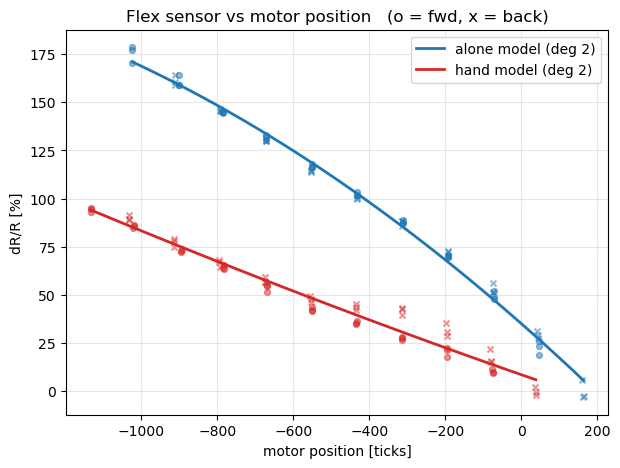

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, d in data.items():
    df, c = d["df"], COLORS[name]
    for dr, mk in (("fwd", "o"), ("back", "x")):
        s = df[df.dir == dr]
        ax.scatter(s.pos, s.x, marker=mk, s=18, color=c, alpha=0.5)
    pp = np.linspace(df.pos.min(), df.pos.max(), 100)
    ax.plot(pp, np.polyval(d["c_fwd"], pp), color=c, lw=2, label=f"{name} model (deg {DEG})")
ax.set_xlabel("motor position [ticks]"); ax.set_ylabel("dR/R [%]")
ax.set_title("Flex sensor vs motor position   (o = fwd, x = back)")
ax.grid(alpha=0.3); ax.legend(); plt.show()

## 3. Hysteresis and repeatability (mean ± std across cycles)

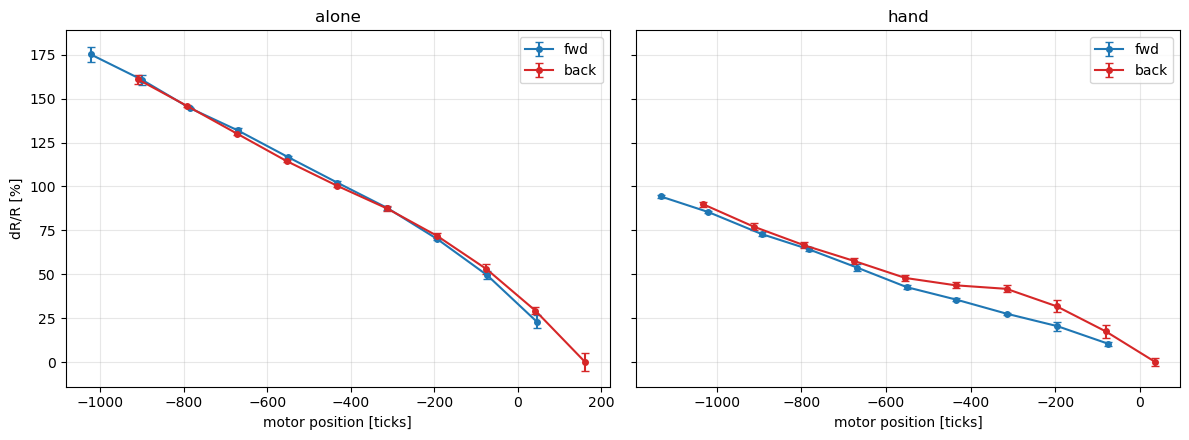

In [20]:
fig, axs = plt.subplots(1, len(data), figsize=(6 * len(data), 4.5), sharey=True, squeeze=False)
for a, (name, d) in zip(axs[0], data.items()):
    g = d["df"].groupby(["dir", "step"]).agg(pos=("pos", "mean"), x=("x", "mean"), sd=("x", "std")).reset_index()
    for dr, c in (("fwd", "tab:blue"), ("back", "tab:red")):
        s = g[g.dir == dr].sort_values("step")
        a.errorbar(s.pos, s.x, yerr=s.sd, color=c, marker="o", ms=4, capsize=3, label=dr)
    a.set_title(name); a.set_xlabel("motor position [ticks]"); a.grid(alpha=0.3); a.legend()
axs[0, 0].set_ylabel("dR/R [%]")
plt.tight_layout(); plt.show()

## 4. Raw time series

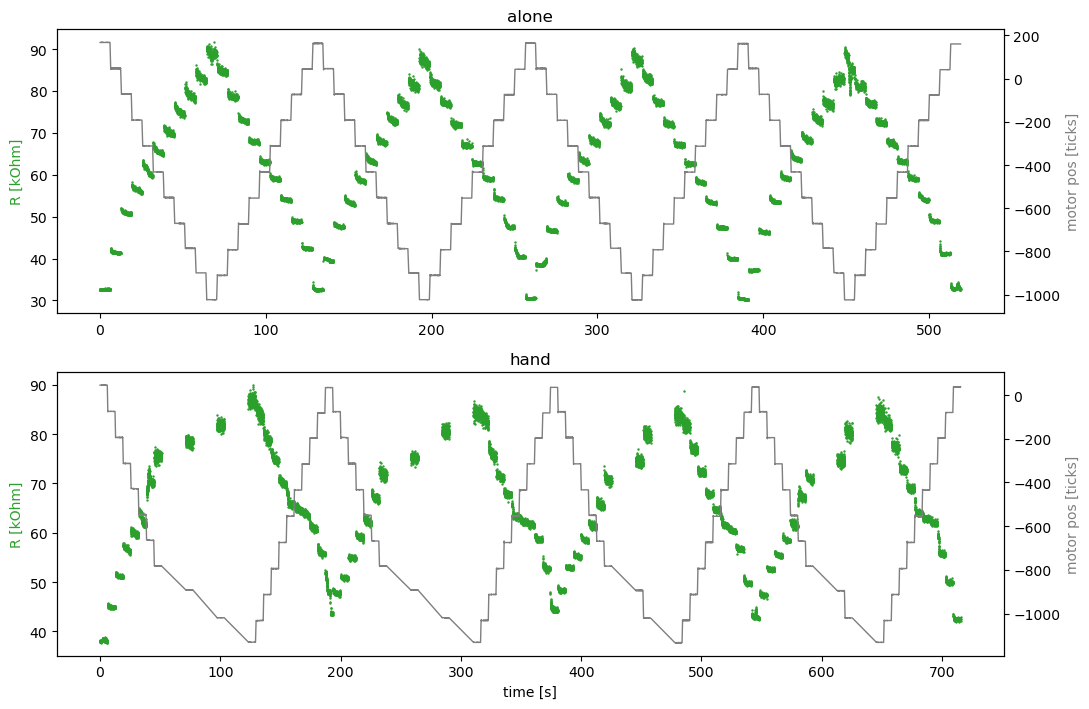

In [21]:
fig, axs = plt.subplots(len(files), 1, figsize=(11, 3.6 * len(files)), squeeze=False)
for a, (name, path) in zip(axs[:, 0], files.items()):
    raw = pd.read_csv(path, comment="#")
    a.plot(raw.t, raw.R / 1000, ".", ms=1.5, color="tab:green")
    a.set_ylabel("R [kOhm]", color="tab:green"); a.set_title(name)
    b = a.twinx()
    p = raw.dropna(subset=["pos"])
    b.plot(p.t, p.pos, color="tab:gray", lw=1); b.set_ylabel("motor pos [ticks]", color="tab:gray")
axs[-1, 0].set_xlabel("time [s]")
plt.tight_layout(); plt.show()

## 5. Use the model
Predict the motor position from a measured flex-sensor resistance.

In [22]:
def pos_from_R(R, setting):
    d = data[setting]
    x = (R - d["R_ref"]) / d["R_ref"] * 100
    return np.polyval(d["c_inv"], x)

for name, d in data.items():
    print(name, "-> pos at R_ref*1.1:", round(float(pos_from_R(d["R_ref"] * 1.1, name))))

alone -> pos at R_ref*1.1: 131
hand -> pos at R_ref*1.1: -52
